# Лабораторная работа № 3. Исследование решающего дерева

**Цель работы** — исследовать решающее дерево для классификации манёвров робота и регрессии загрузки CPU, а также оценить разрыв между обучающей и тестовой выборками.

Дерево последовательно делит данные по порогам отдельных признаков. В классификации разбиение уменьшает неоднородность классов по критерию Джини, а лист предсказывает наиболее частый класс среди попавших в него обучающих объектов. В регрессии разбиение уменьшает квадратичную ошибку, а прогноз листа равен среднему значению цели среди его обучающих объектов.

## 1. Подготовка данных

Загрузим прежние CSV. Для робота возьмём 24 показания датчиков и цель `class`, для CPU — 21 признак и цель `usr`. Используем те же последовательные срезы, что в первых двух работах, с зазором 90 строк перед тестом робота.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

robot = pd.read_csv("data/wall_following_robot_24.csv")
cpu = pd.read_csv("data/cpu_act_44132.csv")

X_robot = robot.drop(columns="class")
y_robot = robot["class"]
X_cpu = cpu.drop(columns="usr")
y_cpu = cpu["usr"]

# Правая граница среза не включается.
robot_train = slice(0, 4274)
robot_test = slice(4364, 5456)
cpu_train = slice(0, 6553)
cpu_test = slice(6553, 8192)

assert len(robot) == robot_test.stop and len(cpu) == cpu_test.stop

X_robot_train, X_robot_test = X_robot.iloc[robot_train], X_robot.iloc[robot_test]
y_robot_train, y_robot_test = y_robot.iloc[robot_train], y_robot.iloc[robot_test]
X_cpu_train, X_cpu_test = X_cpu.iloc[cpu_train], X_cpu.iloc[cpu_test]
y_cpu_train, y_cpu_test = y_cpu.iloc[cpu_train], y_cpu.iloc[cpu_test]

print(f"Робот: {len(X_robot_train)} обучающих и {len(X_robot_test)} тестовых строк.")
print(f"CPU: {len(X_cpu_train)} обучающих и {len(X_cpu_test)} тестовых строк.")

Робот: 4274 обучающих и 1092 тестовых строк.
CPU: 6553 обучающих и 1639 тестовых строк.


## 2. Создание исходного бейзлайна и оценка качества

Обучим классификатор и регрессор на исходных признаках. Оставим стандартные параметры и зададим `random_state=42` для воспроизводимости. Посчитаем метрики на обучении и на тесте, а также выведем фактическую глубину и число листьев.

In [2]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

robot_baseline = DecisionTreeClassifier(random_state=42)
cpu_baseline = DecisionTreeRegressor(random_state=42)
robot_baseline.fit(X_robot_train, y_robot_train)
cpu_baseline.fit(X_cpu_train, y_cpu_train)

y_robot_train_pred = robot_baseline.predict(X_robot_train)
y_robot_pred = robot_baseline.predict(X_robot_test)
y_cpu_train_pred = cpu_baseline.predict(X_cpu_train)
y_cpu_pred = cpu_baseline.predict(X_cpu_test)

samples = ["Обучение", "Тест"]
baseline_classification = pd.DataFrame([
    {"Accuracy": accuracy_score(actual, predicted),
     "F1-macro": f1_score(actual, predicted, average="macro")}
    for actual, predicted in [
        (y_robot_train, y_robot_train_pred), (y_robot_test, y_robot_pred),
    ]
], index=pd.Index(samples, name="Выборка"))

baseline_regression = pd.DataFrame([
    {"MAE, п. п.": mean_absolute_error(actual, predicted),
     "RMSE, п. п.": mean_squared_error(actual, predicted) ** 0.5,
     "R²": r2_score(actual, predicted)}
    for actual, predicted in [
        (y_cpu_train, y_cpu_train_pred), (y_cpu_test, y_cpu_pred),
    ]
], index=pd.Index(samples, name="Выборка"))

tree_structure = pd.DataFrame([
    {"Глубина": model.get_depth(), "Листья": model.get_n_leaves()}
    for model in [robot_baseline, cpu_baseline]
], index=pd.Index(["Классификатор", "Регрессор"], name="Модель"))

display(baseline_classification.round(4))
display(baseline_regression.round(4))
display(tree_structure)

,Accuracy,F1-macro
Выборка,,
Обучение,1.0000,1.0000
Тест,0.9844,0.9801


,"MAE, п. п.","RMSE, п. п.",R²
Выборка,,,
Обучение,0.000,0.0000,1.0000
Тест,2.579,3.7752,0.9514


,Глубина,Листья
Модель,,
Классификатор,11,32
Регрессор,28,3528


### Графики качества на тесте

Построим матрицу ошибок по четырём манёврам. Для регрессии сопоставим фактические и предсказанные значения `usr`. Диагональ соответствует точному прогнозу.

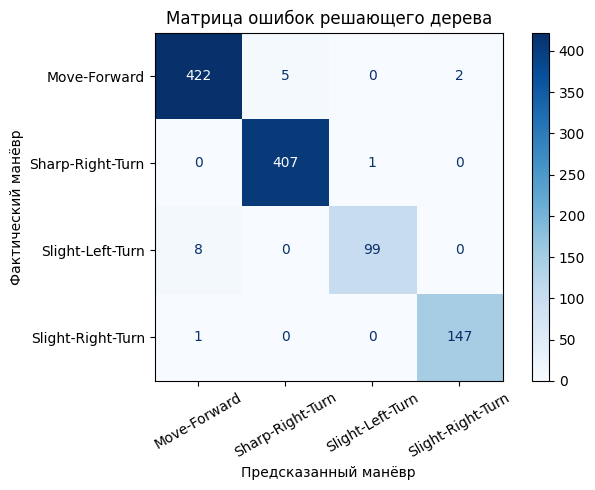

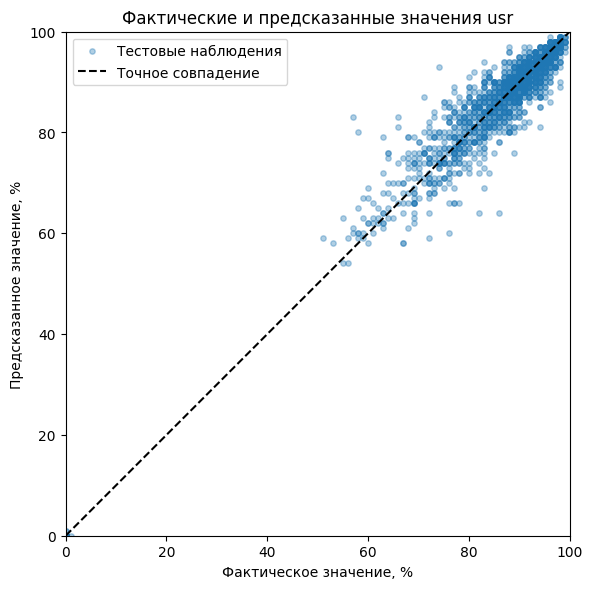

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_robot_test, y_robot_pred, labels=robot_baseline.classes_,
    cmap="Blues", values_format="d", xticks_rotation=30, ax=ax,
)
ax.set(title="Матрица ошибок решающего дерева",
       xlabel="Предсказанный манёвр", ylabel="Фактический манёвр")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_cpu_test, y_cpu_pred, s=15, alpha=0.35, label="Тестовые наблюдения")
ax.plot([0, 100], [0, 100], "--", color="black", label="Точное совпадение")
ax.set(title="Фактические и предсказанные значения usr",
       xlabel="Фактическое значение, %", ylabel="Предсказанное значение, %",
       xlim=(0, 100), ylim=(0, 100), aspect="equal")
ax.legend()
fig.tight_layout()
plt.show()

### Первые три уровня деревьев

В `plot_tree` укажем глубину отображения 2, чтобы показать корень и два следующих уровня. Многоточия обозначают скрытые ветви. Настройка относится только к графику, обученные деревья сохраняют полную глубину.

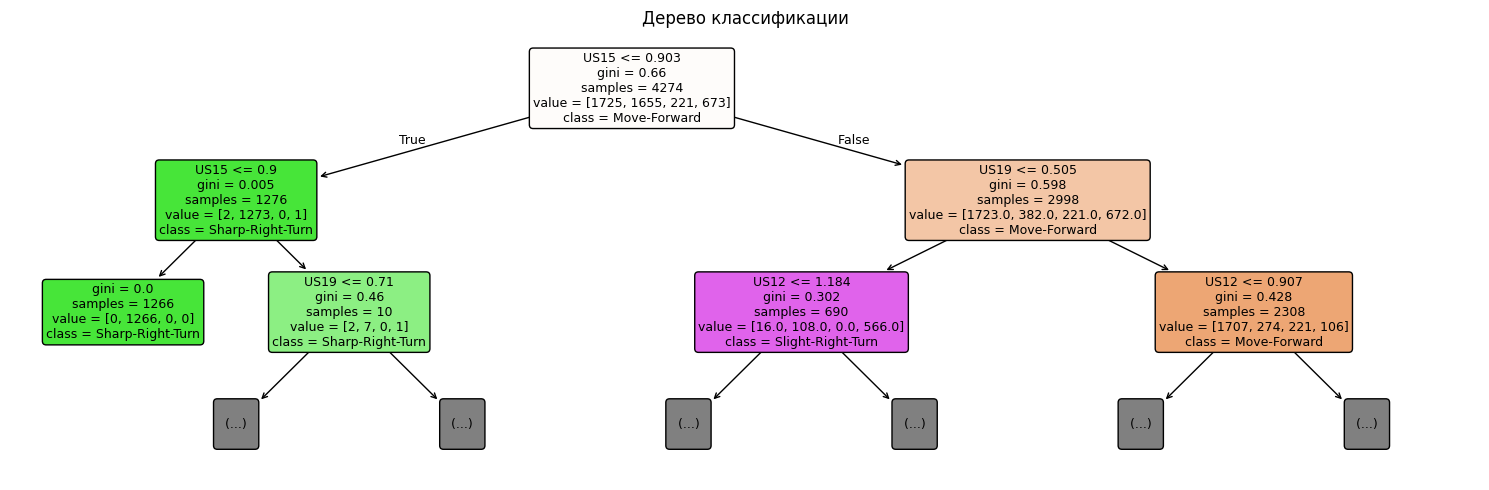

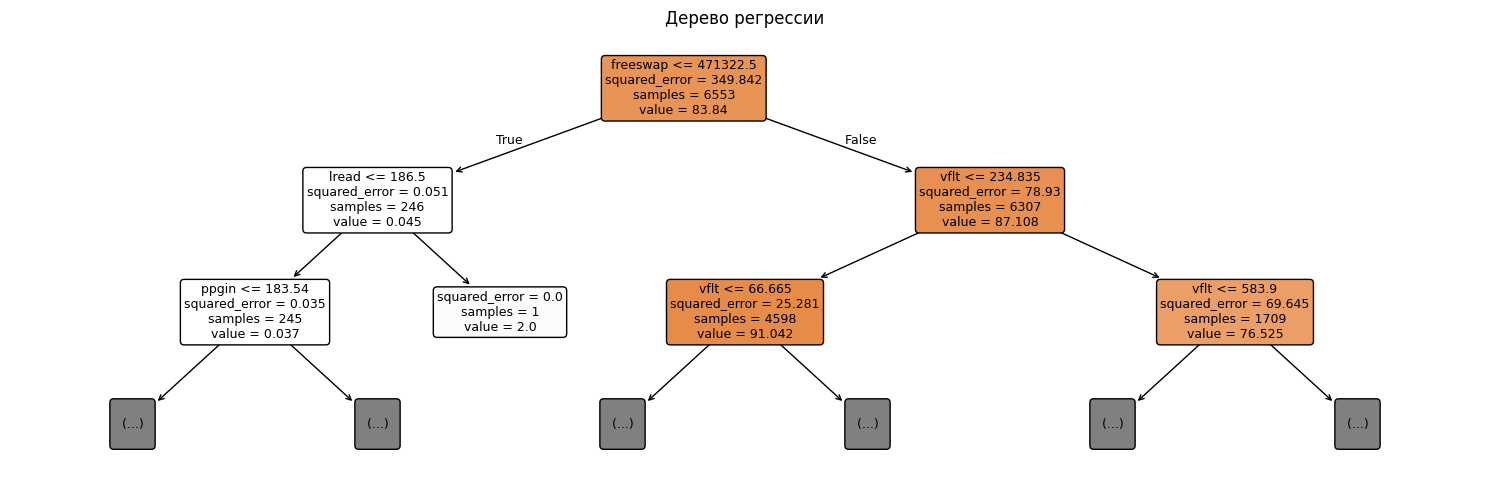

In [4]:
for title, model, features, classes in [
    ("Дерево классификации", robot_baseline, X_robot_train, robot_baseline.classes_.tolist()),
    ("Дерево регрессии", cpu_baseline, X_cpu_train, None),
]:
    fig, ax = plt.subplots(figsize=(15, 5))
    plot_tree(
        model, max_depth=2, feature_names=features.columns.tolist(),
        class_names=classes, filled=True, rounded=True, fontsize=9, ax=ax,
    )
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

### Выводы

- **Классификация.** Глубина дерева — 11, число листьев — 32. От обучения к тесту Accuracy снизилась с 100,00% до 98,44%, а F1-macro изменилась с 1,0000 до 0,9801.
- **Регрессия.** Глубина дерева — 28, число листьев — 3528. При переходе от обучения к тесту MAE составила 0,0000 → 2,5790 п. п., RMSE — 0,0000 → 3,7752 п. п., R² — 1,0000 → 0,9514.

Оба дерева практически точно воспроизводят ответы на обучении, а на отложенных блоках качество заметно ниже. Такой разрыв согласуется с переобучением. На него могут также влиять различия между последовательными блоками данных.

## 3. Улучшение бейзлайна

1. Ограничение максимальной глубины (`max_depth`) уменьшит переобучение.
2. Увеличение минимального количества объектов в листе (`min_samples_leaf`) повысит устойчивость модели.
3. Увеличение минимального количества объектов для разбиения узла (`min_samples_split`) уменьшит сложность дерева.

Переберём 60 сочетаний параметров для каждой задачи. Используем три последовательных разбиения обучающей выборки и сохраним зазор 90 строк для робота. Максимизируем F1-macro для классификации и минимизируем MAE для регрессии. `GridSearchCV` максимизирует оценку, поэтому для MAE передаём `neg_mean_absolute_error` и возвращаем обычный знак при выводе. Победителей переобучим на всей обучающей выборке через `refit=True`. Масштабирование не требуется, поскольку деревья используют пороги отдельных признаков.

In [5]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

param_grid = {
    "max_depth": [3, 5, 10, 15, None],
    "min_samples_leaf": [1, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
}

robot_search = GridSearchCV(
    robot_baseline, param_grid, scoring="f1_macro",
    cv=TimeSeriesSplit(n_splits=3, gap=90), refit=True,
    return_train_score=True,
)
cpu_search = GridSearchCV(
    cpu_baseline, param_grid, scoring="neg_mean_absolute_error",
    cv=TimeSeriesSplit(n_splits=3), refit=True, return_train_score=True,
)

robot_search.fit(X_robot_train, y_robot_train)
cpu_search.fit(X_cpu_train, y_cpu_train)

best_robot_tree_params = dict(robot_search.best_params_, random_state=42)
best_cpu_tree_params = dict(cpu_search.best_params_, random_state=42)
robot_improved = robot_search.best_estimator_
cpu_improved = cpu_search.best_estimator_

print(f"Робот: {best_robot_tree_params}, F1-macro на CV = {robot_search.best_score_:.4f}")
print(f"CPU: {best_cpu_tree_params}, MAE на CV = {-cpu_search.best_score_:.4f} п. п.")

Робот: {'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 2, 'random_state': 42}, F1-macro на CV = 0.9595
CPU: {'max_depth': 10, 'min_samples_leaf': 10, 'min_samples_split': 2, 'random_state': 42}, MAE на CV = 2.2968 п. п.


### Проверка гипотез

Для каждого параметра оставим два других на значениях бейзлайна. Переобучение оценим по разрыву между средними обучающей и валидационной метриками на фолдах. Меньший разрыв будем считать положительным признаком, если качество на валидации сохраняется или растёт. Устойчивость оценим по стандартному отклонению метрики на трёх валидационных блоках. Для оценки сложности измерим глубину и число листьев после обучения на всей обучающей выборке.

In [6]:
baseline_params = {"max_depth": None, "min_samples_leaf": 1, "min_samples_split": 2}

for title, search, X_train, y_train, metric, sign in [
    ("Робот", robot_search, X_robot_train, y_robot_train, "F1-macro", 1),
    ("CPU", cpu_search, X_cpu_train, y_cpu_train, "MAE, п. п.", -1),
]:
    cv_results = pd.DataFrame(search.cv_results_)
    print(f"{title} — {metric}")
    for param, values in param_grid.items():
        rows = []
        for value in values:
            params = dict(baseline_params)
            params[param] = value
            result = cv_results.loc[cv_results["params"].map(lambda p: p == params)].iloc[0]
            model = type(search.estimator)(random_state=42, **params)
            model.fit(X_train, y_train)
            rows.append({
                param: str(value),
                "Обучение (CV)": sign * result["mean_train_score"],
                "Валидация (CV)": sign * result["mean_test_score"],
                "Разрыв (CV)": result["mean_train_score"] - result["mean_test_score"],
                "Ст. откл. на валидации": result["std_test_score"],
                "Глубина": model.get_depth(),
                "Листья": model.get_n_leaves(),
            })
        display(pd.DataFrame(rows).set_index(param).round(4))

Робот — F1-macro


,Обучение (CV),Валидация (CV),Разрыв (CV),Ст. откл. на валидации,Глубина,Листья
max_depth,,,,,,
3,0.6891,0.6901,-0.0010,0.0111,3,7
5,0.9494,0.9109,0.0385,0.0109,5,16
10,0.9901,0.9404,0.0497,0.0302,10,31
15,1.0000,0.9591,0.0409,0.0209,11,32
None,1.0000,0.9591,0.0409,0.0209,11,32


,Обучение (CV),Валидация (CV),Разрыв (CV),Ст. откл. на валидации,Глубина,Листья
min_samples_leaf,,,,,,
1,1.0000,0.9591,0.0409,0.0209,11,32
3,0.9950,0.9448,0.0501,0.0291,11,29
5,0.9881,0.9579,0.0301,0.0225,10,28
10,0.9792,0.9595,0.0197,0.0273,10,25


,Обучение (CV),Валидация (CV),Разрыв (CV),Ст. откл. на валидации,Глубина,Листья
min_samples_split,,,,,,
2,1.0000,0.9591,0.0409,0.0209,11,32
5,0.9985,0.9453,0.0532,0.0275,11,29
10,0.9948,0.9505,0.0443,0.0221,11,29


CPU — MAE, п. п.


,Обучение (CV),Валидация (CV),Разрыв (CV),Ст. откл. на валидации,Глубина,Листья
max_depth,,,,,,
3,3.4805,3.5962,0.1157,0.0177,3,7
5,2.4781,2.6447,0.1665,0.0486,5,22
10,1.1844,2.3668,1.1824,0.0993,10,415
15,0.2430,2.5105,2.2675,0.1165,15,2164
None,-0.0000,2.5358,2.5358,0.1062,28,3528


,Обучение (CV),Валидация (CV),Разрыв (CV),Ст. откл. на валидации,Глубина,Листья
min_samples_leaf,,,,,,
1,-0.0000,2.5358,2.5358,0.1062,28,3528
3,0.7316,2.3839,1.6524,0.0679,24,1717
5,1.0896,2.3559,1.2663,0.0885,22,1015
10,1.4894,2.3056,0.8162,0.0684,19,502


,Обучение (CV),Валидация (CV),Разрыв (CV),Ст. откл. на валидации,Глубина,Листья
min_samples_split,,,,,,
2,-0.0000,2.5358,2.5358,0.1062,28,3528
5,0.3402,2.4979,2.1577,0.0917,27,2317
10,0.7779,2.4382,1.6603,0.0903,27,1340


### Сравнение моделей на обучении и тесте

Рассчитаем те же метрики, что в разделе 2. Используем прежние обучающие и тестовые срезы. Сопоставим показатели качества и размеры деревьев.

In [7]:
improved_classification = pd.DataFrame([
    {"Accuracy": accuracy_score(actual, predicted),
     "F1-macro": f1_score(actual, predicted, average="macro")}
    for actual, predicted in [
        (y_robot_train, robot_improved.predict(X_robot_train)),
        (y_robot_test, robot_improved.predict(X_robot_test)),
    ]
], index=baseline_classification.index)

improved_regression = pd.DataFrame([
    {"MAE, п. п.": mean_absolute_error(actual, predicted),
     "RMSE, п. п.": mean_squared_error(actual, predicted) ** 0.5,
     "R²": r2_score(actual, predicted)}
    for actual, predicted in [
        (y_cpu_train, cpu_improved.predict(X_cpu_train)),
        (y_cpu_test, cpu_improved.predict(X_cpu_test)),
    ]
], index=baseline_regression.index)

improved_structure = pd.DataFrame([
    {"Глубина": model.get_depth(), "Листья": model.get_n_leaves()}
    for model in [robot_improved, cpu_improved]
], index=tree_structure.index)

versions = ["Бейзлайн", "После подбора"]
display(pd.concat([baseline_classification, improved_classification], axis=1, keys=versions).round(4))
display(pd.concat([baseline_regression, improved_regression], axis=1, keys=versions).round(4))
display(pd.concat([tree_structure, improved_structure], axis=1, keys=versions))

Бейзлайн          После подбора         
         Accuracy F1-macro      Accuracy F1-macro
Выборка                                          
Обучение   1.0000   1.0000        0.9949   0.9914
Тест       0.9844   0.9801        0.9780   0.9701

Бейзлайн                     После подбора                    
         MAE, п. п. RMSE, п. п.      R²    MAE, п. п. RMSE, п. п.      R²
Выборка                                                                  
Обучение      0.000      0.0000  1.0000        1.6491      2.2734  0.9852
Тест          2.579      3.7752  0.9514        2.2459      3.1898  0.9653

Бейзлайн        После подбора       
               Глубина Листья       Глубина Листья
Модель                                            
Классификатор       11     32            10     25
Регрессор           28   3528            10    221

### Сравнительные графики

Покажем все метрики на обучении и тесте. На отдельных графиках сравним глубину и число листьев.

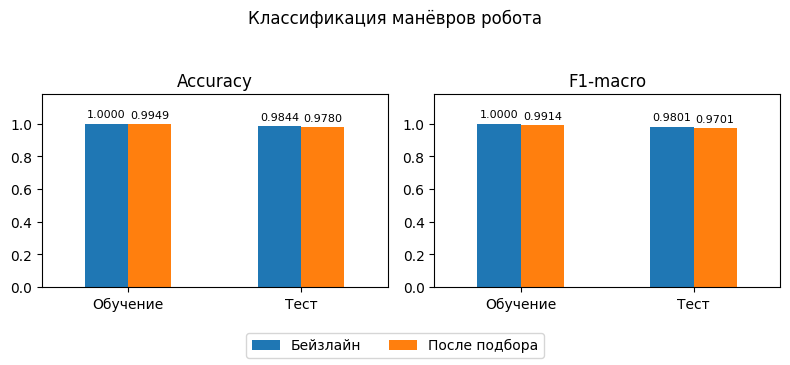

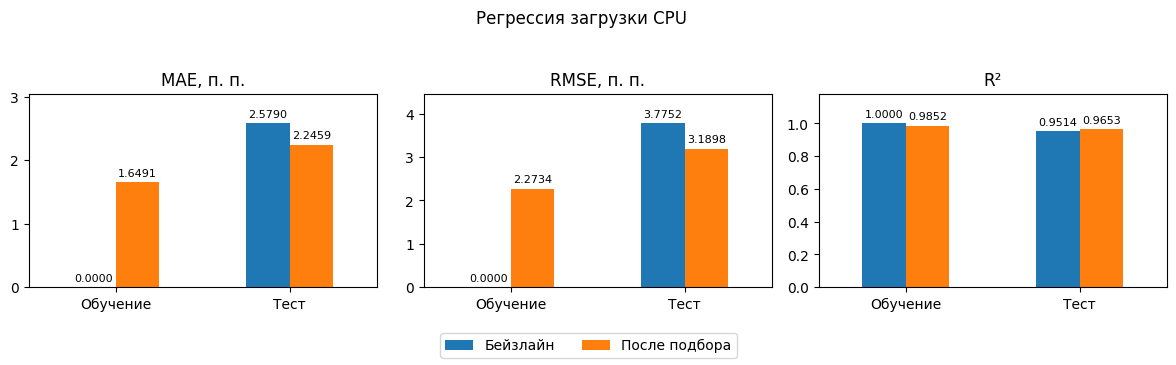

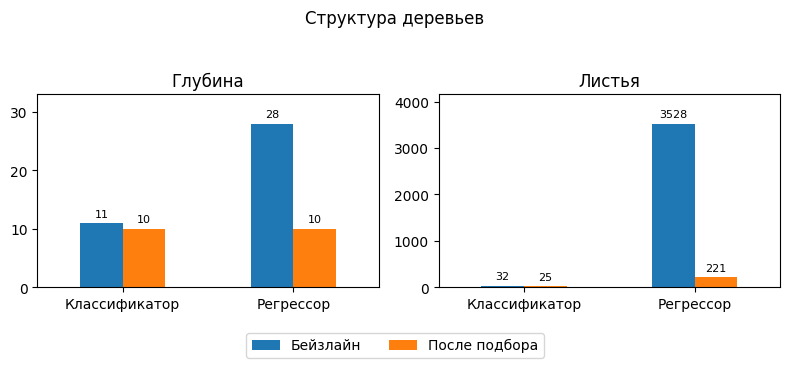

In [8]:
for title, baseline, improved in [
    ("Классификация манёвров робота", baseline_classification, improved_classification),
    ("Регрессия загрузки CPU", baseline_regression, improved_regression),
    ("Структура деревьев", tree_structure, improved_structure),
]:
    fig, axes = plt.subplots(1, len(baseline.columns), figsize=(4 * len(baseline.columns), 3.6))
    for ax, metric in zip(axes, baseline.columns):
        comparison = pd.DataFrame({versions[0]: baseline[metric], versions[1]: improved[metric]})
        comparison.plot.bar(ax=ax, rot=0, title=metric, legend=False, xlabel="")
        for bars in ax.containers:
            labels = [f"{value:.4f}" if abs(value) < 10 else f"{value:.0f}" for value in bars.datavalues]
            ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
        ax.margins(y=0.18)
    fig.suptitle(title)
    fig.legend(axes[0].containers, versions, loc="lower center", ncol=2)
    fig.tight_layout(rect=(0, 0.10, 1, 0.94))
    plt.show()

### Выводы

1. **Ограничение глубины помогло регрессии.** При `max_depth=10` разрыв MAE на кросс-валидации уменьшился с 2,5358 до 1,1824 п. п., а валидационная MAE — с 2,5358 до 2,3668 п. п. Для робота ни одно ограничение глубины само по себе не уменьшило разрыв при сохранении валидационного F1-macro.
2. **Устойчивость выросла у регрессора.** При увеличении `min_samples_leaf` с 1 до 10 стандартное отклонение MAE между блоками снизилось с 0,1062 до 0,0684 п. п. У классификатора разброс F1-macro вырос при всех проверенных увеличениях этого параметра.
3. **Повышение `min_samples_split` упростило оба дерева.** При увеличении порога с 2 до 10 число листьев уменьшилось с 32 до 29 у классификатора и с 3528 до 1340 у регрессора. Глубина классификатора осталась равна 11, а глубина регрессора уменьшилась с 28 до 27.

- **Классификация.** После совместного подбора дерево сократилось с 32 до 25 листьев, глубина — с 11 до 10. Средний F1-macro на кросс-валидации немного вырос с 0,9591 до 0,9595. На тесте улучшения нет. F1-macro снизился с 0,9801 до 0,9701, Accuracy — с 98,44% до 97,80%.
- **Регрессия.** После подбора дерево сократилось с 3528 до 221 листа, глубина — с 28 до 10. На тесте MAE снизилась с 2,5790 до 2,2459 п. п., RMSE — с 3,7752 до 3,1898 п. п., а R² вырос с 0,9514 до 0,9653.

## 4. Самостоятельная реализация алгоритма

Для **классификации** неоднородность узла измерим критерием Джини $G = 1 - \sum_k p_k^2$, где $p_k$ — доля объектов класса $k$. Выберем разбиение с наименьшим средним Джини дочерних узлов, взвешенным по числу объектов. Лист предсказывает класс большинства. При равенстве голосов выбирается первый класс в порядке сортировки меток.

Для **регрессии** минимизируем сумму квадратов отклонений в дочерних узлах. В каждом узле она равна $\sum_i y_i^2 - (\sum_i y_i)^2 / n$, где $n$ — число объектов. Прогноз листа — среднее целевое значение.

Для каждого признака отсортируем строки узла и проверим границы между соседними различными значениями. Накопительные количества классов или суммы целей и их квадратов позволяют вычислить критерий сразу для всех допустимых границ. Перебор признаков в случайном порядке задаёт воспроизводимый выбор при равных оценках. Строим дерево рекурсивно, пока позволяют ограничения на глубину и размер узлов.

In [9]:
import numpy as np


class _SimpleTree:
    _classification = False

    def __init__(self, max_depth=None, min_samples_leaf=1, min_samples_split=2,
                 random_state=None):
        self.max_depth = max_depth
        self.min_samples_leaf = min_samples_leaf
        self.min_samples_split = min_samples_split
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        if X.ndim != 2 or not X.size or y.shape != (len(X),):
            raise ValueError("Нужны непустая матрица признаков и одномерная цель.")
        if not np.isfinite(X).all():
            raise ValueError("Признаки должны быть конечными числами.")
        for name, value, minimum in [
            ("max_depth", self.max_depth, 1),
            ("min_samples_leaf", self.min_samples_leaf, 1),
            ("min_samples_split", self.min_samples_split, 2),
        ]:
            if name == "max_depth" and value is None:
                continue
            if not isinstance(value, (int, np.integer)) or value < minimum:
                raise ValueError(f"{name} должен быть целым числом от {minimum}.")

        if self._classification:
            self.classes_, y = np.unique(y, return_inverse=True)
        else:
            y = y.astype(float)
            if not np.isfinite(y).all():
                raise ValueError("Цель регрессии должна содержать конечные числа.")

        self.n_features_in_ = X.shape[1]
        self.depth_ = 0
        self.n_leaves_ = 0
        self._rng = np.random.default_rng(self.random_state)
        self.tree_ = self._grow(X, y, depth=0)
        return self

    def _best_split(self, X, y):
        n = len(y)
        best_cost = np.inf
        best_split = None
        if self._classification:
            targets = y[:, None] == np.arange(len(self.classes_))
        else:
            # Центрирование снижает потерю точности при вычитании близких сумм.
            targets = y - y.mean()

        for feature in self._rng.permutation(X.shape[1]):
            order = np.argsort(X[:, feature], kind="stable")
            values = X[order, feature]
            cuts = np.flatnonzero(values[:-1] < values[1:]) + 1
            cuts = cuts[(cuts >= self.min_samples_leaf) & (n - cuts >= self.min_samples_leaf)]
            if cuts.size == 0:
                continue

            sorted_targets = targets[order]
            prefix = np.cumsum(sorted_targets, axis=0)
            left = prefix[cuts - 1]
            right = prefix[-1] - left
            if self._classification:
                # Взвешенный Джини с общим множителем n.
                costs = n - (left ** 2).sum(axis=1) / cuts - (right ** 2).sum(axis=1) / (n - cuts)
            else:
                squared_prefix = np.cumsum(sorted_targets ** 2)
                left_sse = squared_prefix[cuts - 1] - left ** 2 / cuts
                right_sse = squared_prefix[-1] - squared_prefix[cuts - 1] - right ** 2 / (n - cuts)
                costs = np.maximum(left_sse, 0) + np.maximum(right_sse, 0)

            i = np.argmin(costs)
            if costs[i] < best_cost:
                best_cost = costs[i]
                cut = cuts[i]
                lower, upper = values[cut - 1], values[cut]
                threshold = lower / 2 + upper / 2
                # Округление не должно перенести правую группу влево.
                if not lower <= threshold < upper:
                    threshold = lower
                best_split = (feature, threshold)
        return best_split

    def _grow(self, X, y, depth):
        self.depth_ = max(self.depth_, depth)
        stop = (
            (self.max_depth is not None and depth >= self.max_depth)
            or len(y) < max(self.min_samples_split, 2 * self.min_samples_leaf)
            or np.all(y == y[0])
        )
        split = None if stop else self._best_split(X, y)
        if split is None:
            self.n_leaves_ += 1
            if self._classification:
                return np.bincount(y).argmax()
            return y.mean()

        feature, threshold = split
        left = X[:, feature] <= threshold
        return (
            feature, threshold,
            self._grow(X[left], y[left], depth + 1),
            self._grow(X[~left], y[~left], depth + 1),
        )

    def predict(self, X):
        if not hasattr(self, "tree_"):
            raise ValueError("Сначала вызовите fit.")
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != self.n_features_in_ or not np.isfinite(X).all():
            raise ValueError("Ожидается матрица конечных чисел с прежним числом признаков.")
        predictions = []
        for row in X:
            node = self.tree_
            while isinstance(node, tuple):
                feature, threshold, left, right = node
                node = left if row[feature] <= threshold else right
            predictions.append(node)
        if self._classification:
            return self.classes_[np.asarray(predictions, dtype=int)]
        return np.asarray(predictions, dtype=float)

    def get_depth(self):
        return self.depth_

    def get_n_leaves(self):
        return self.n_leaves_


class SimpleTreeClassifier(_SimpleTree):
    _classification = True


class SimpleTreeRegressor(_SimpleTree):
    pass

### Проверка на искусственных данных

Проверим выбор информативного признака и порога при повторяющихся значениях, голосование большинства и среднее в листе. Дополнительно проверим ограничения на размер узлов, лист без допустимого разбиения, воспроизводимость и рекурсию на задаче XOR.

In [10]:
X_small = [[1, 0], [1, 0], [1, 0], [1, 2], [1, 2], [1, 2]]
X_check = [[1, 0.5], [1, 1], [1, 1.5]]
y_class_small = ["А", "Б", "А", "Б", "Б", "А"]
y_reg_small = [0, 0, 3, 8, 10, 12]

small_classifier = SimpleTreeClassifier(max_depth=1, random_state=42).fit(X_small, y_class_small)
small_regressor = SimpleTreeRegressor(max_depth=1, random_state=42).fit(X_small, y_reg_small)
np.testing.assert_array_equal(small_classifier.predict(X_check), ["А", "А", "Б"])
np.testing.assert_allclose(small_regressor.predict(X_check), [1, 1, 10])
for model in [small_classifier, small_regressor]:
    assert model.tree_[:2] == (1, 1.0)
    assert (model.get_depth(), model.get_n_leaves()) == (1, 2)

leaf_classifier = SimpleTreeClassifier(min_samples_leaf=4).fit(X_small, y_class_small)
leaf_regressor = SimpleTreeRegressor(min_samples_split=7).fit(X_small, y_reg_small)
assert leaf_classifier.get_n_leaves() == leaf_regressor.get_n_leaves() == 1
np.testing.assert_array_equal(leaf_classifier.predict(X_check), ["А", "А", "А"])
np.testing.assert_allclose(leaf_regressor.predict(X_check), [5.5, 5.5, 5.5])
constant_regressor = SimpleTreeRegressor().fit([[1], [1]], [2, 6])
assert constant_regressor.get_depth() == 0
np.testing.assert_allclose(constant_regressor.predict([[1]]), [4])

X_xor = [[0, 0], [0, 1], [1, 0], [1, 1]]
y_xor = [0, 1, 1, 0]
xor_tree = SimpleTreeClassifier(random_state=42).fit(X_xor, y_xor)
assert xor_tree.tree_ == SimpleTreeClassifier(random_state=42).fit(X_xor, y_xor).tree_
assert (xor_tree.get_depth(), xor_tree.get_n_leaves()) == (2, 4)
np.testing.assert_array_equal(xor_tree.predict(X_xor), y_xor)
print("Все проверки пройдены.")

Все проверки пройдены.


### Обучение и итоговые таблицы

Обучим собственные деревья с исходными настройками и с параметрами, выбранными на кросс-валидации в разделе 3. Оценим все четыре варианта для каждой задачи на прежних срезах. В таблицах глубина и число листьев относятся к модели, обученной на всей обучающей выборке.

In [11]:
custom_robot = SimpleTreeClassifier(random_state=42).fit(X_robot_train, y_robot_train)
custom_cpu = SimpleTreeRegressor(random_state=42).fit(X_cpu_train, y_cpu_train)
custom_robot_improved = SimpleTreeClassifier(**best_robot_tree_params).fit(X_robot_train, y_robot_train)
custom_cpu_improved = SimpleTreeRegressor(**best_cpu_tree_params).fit(X_cpu_train, y_cpu_train)

model_names = ["Исходная sklearn", "Улучшенная sklearn", "Собственная", "Улучшенная собственная"]
classification_rows = []
for name, model in zip(model_names, [robot_baseline, robot_improved, custom_robot, custom_robot_improved]):
    for sample, X, y in [
        ("Обучение", X_robot_train, y_robot_train), ("Тест", X_robot_test, y_robot_test),
    ]:
        predicted = model.predict(X)
        classification_rows.append({
            "Модель": name, "Выборка": sample,
            "Accuracy": accuracy_score(y, predicted),
            "F1-macro": f1_score(y, predicted, average="macro"),
            "Глубина": model.get_depth(), "Листья": model.get_n_leaves(),
        })

regression_rows = []
for name, model in zip(model_names, [cpu_baseline, cpu_improved, custom_cpu, custom_cpu_improved]):
    for sample, X, y in [
        ("Обучение", X_cpu_train, y_cpu_train), ("Тест", X_cpu_test, y_cpu_test),
    ]:
        predicted = model.predict(X)
        regression_rows.append({
            "Модель": name, "Выборка": sample,
            "MAE, п. п.": mean_absolute_error(y, predicted),
            "RMSE, п. п.": mean_squared_error(y, predicted) ** 0.5,
            "R²": r2_score(y, predicted),
            "Глубина": model.get_depth(), "Листья": model.get_n_leaves(),
        })

final_classification = pd.DataFrame(classification_rows).set_index(["Модель", "Выборка"])
final_regression = pd.DataFrame(regression_rows).set_index(["Модель", "Выборка"])
display(final_classification.round(4))
display(final_regression.round(4))

Accuracy  F1-macro  Глубина  Листья
Модель                 Выборка                                      
Исходная sklearn       Обучение    1.0000    1.0000       11      32
                       Тест        0.9844    0.9801       11      32
Улучшенная sklearn     Обучение    0.9949    0.9914       10      25
                       Тест        0.9780    0.9701       10      25
Собственная            Обучение    1.0000    1.0000       11      32
                       Тест        0.9835    0.9787       11      32
Улучшенная собственная Обучение    0.9949    0.9914       10      25
                       Тест        0.9771    0.9689       10      25

MAE, п. п.  RMSE, п. п.      R²  Глубина  \
Модель                 Выборка                                              
Исходная sklearn       Обучение      0.0000       0.0000  1.0000       28   
                       Тест          2.5790       3.7752  0.9514       28   
Улучшенная sklearn     Обучение      1.6491       2.2734  0.9852       10   
                       Тест          2.2459       3.1898  0.9653       10   
Собственная            Обучение      0.0000       0.0000  1.0000       28   
                       Тест          2.5137       3.6520  0.9545       28   
Улучшенная собственная Обучение      1.6493       2.2734  0.9852       10   
                       Тест          2.2459       3.1890  0.9653       10   

                                 Листья  
Модель                 Выборка           
Исходная sklearn       Обучение    3528  
                       Тест        3528  
Улучшенная sklearn     Обучение     221  
                       Тест         221  
Собственная            Обучение    3533  
                       Тест        3533  
Улучшенная собственная Обучение     221  
                       Тест         221

### Сравнительные графики

Сравним качество четырёх моделей на обучении и тесте, а затем сопоставим глубину и число листьев. Для количества листьев используем логарифмическую шкалу, чтобы были видны и небольшие деревья.

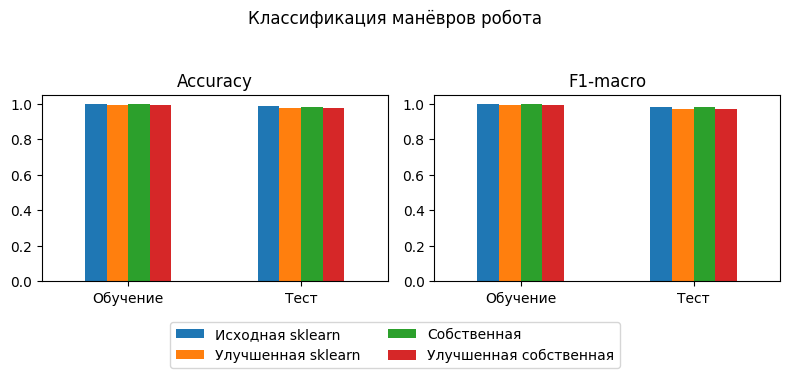

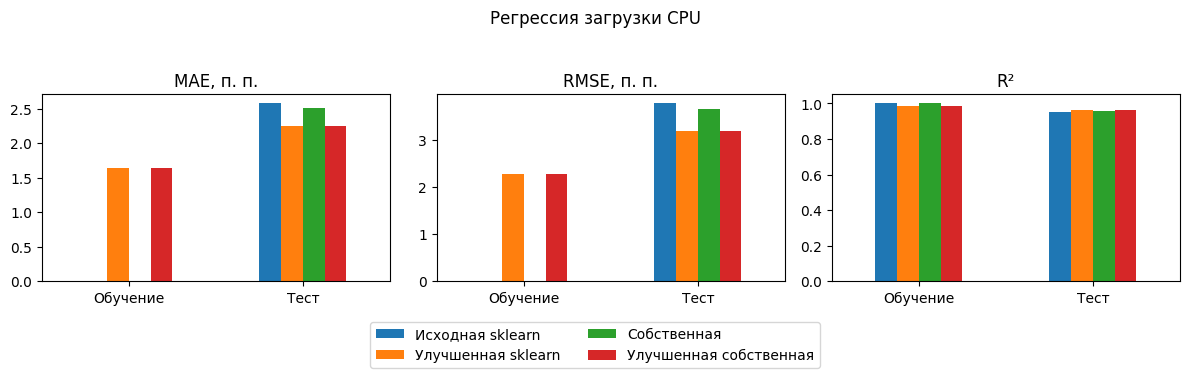

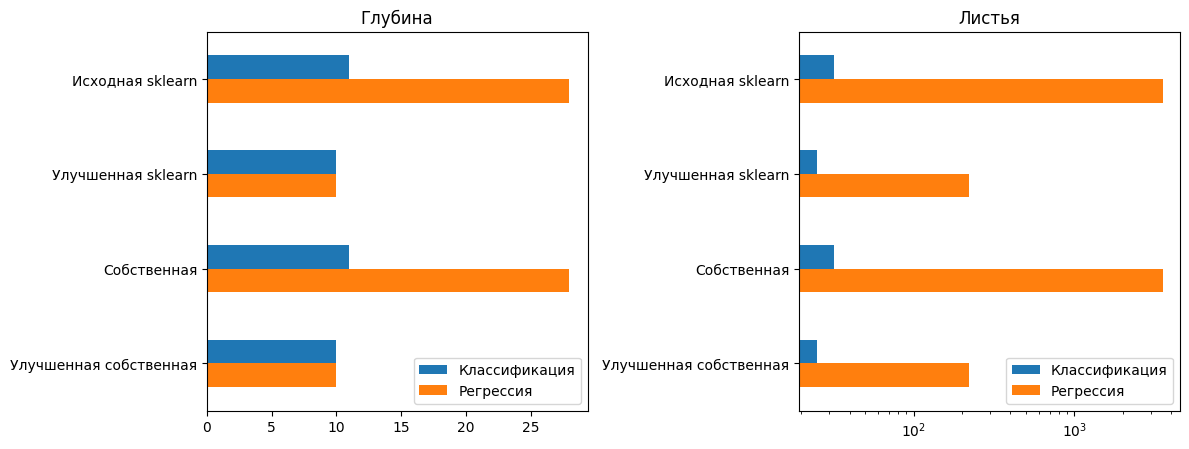

In [12]:
for title, results, metrics in [
    ("Классификация манёвров робота", final_classification, ["Accuracy", "F1-macro"]),
    ("Регрессия загрузки CPU", final_regression, ["MAE, п. п.", "RMSE, п. п.", "R²"]),
]:
    fig, axes = plt.subplots(1, len(metrics), figsize=(4 * len(metrics), 3.7))
    for ax, metric in zip(axes, metrics):
        scores = results[metric].unstack("Модель").reindex(index=samples, columns=model_names)
        scores.plot.bar(ax=ax, rot=0, title=metric, legend=False, xlabel="")
    fig.suptitle(title)
    fig.legend(axes[0].containers, model_names, loc="lower center", ncol=2)
    fig.tight_layout(rect=(0, 0.14, 1, 0.94))
    plt.show()

structure = pd.DataFrame({
    "Классификация": final_classification.xs("Тест", level="Выборка")[["Глубина", "Листья"]].stack(),
    "Регрессия": final_regression.xs("Тест", level="Выборка")[["Глубина", "Листья"]].stack(),
})
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, metric in zip(axes, ["Глубина", "Листья"]):
    values = structure.xs(metric, level=1).reindex(model_names)
    values.plot.barh(ax=ax, title=metric, logx=(metric == "Листья"), ylabel="")
    ax.invert_yaxis()
fig.tight_layout()
plt.show()

### Общий вывод по лабораторной работе

- **Классификация.** Собственное дерево с исходными настройками получило F1-macro 0,9787 на тесте, а исходное дерево sklearn — 0,9801. После переноса параметров из раздела 3 оба дерева стали меньше (глубина 11 → 10, число листьев 32 → 25), но F1-macro на тесте снизился до 0,9689 у собственного дерева и до 0,9701 у sklearn.
- **Регрессия.** У собственного дерева после ограничения глубины и увеличения минимального размера листа MAE на тесте снизилась с 2,5137 до 2,2459 п. п., а число листьев — с 3533 до 221. У sklearn MAE также снизилась (с 2,5790 до 2,2459 п. п. при округлении до четырёх знаков). Оба дерева после подбора имеют глубину 10.

Близкие метрики получены при одинаковых критериях разбиения и ограничениях. Различия возможны из-за порядка перебора признаков при равных оценках и особенностей вычислений с плавающей точкой. Поэтому даже деревья одинаковой глубины и с одинаковым числом листьев могут проводить разные границы и давать разные предсказания.

Ограничения дерева заметно снизили тестовую ошибку регрессии, но упрощение классификатора сопровождалось снижением тестового F1-macro. Параметры для собственных деревьев перенесены из кросс-валидации sklearn без дополнительного подбора.